# 幫買家 GPT 選一個 tokenizer

**Sell Anything 的第二本筆記本。** 上一本訓練了「看圖」的模型，這一本開始做「說話」的模型。
在訓練 GPT 之前，第一件事是決定：**文字要怎麼切成 token**。

你已經在 Karpathy 的分詞器講義裡學過 BPE 怎麼運作（合併最常出現的一對、一直重複）。
所以這本**不重講演算法**，而是回答一個工程問題：

> 我們的模型很小（約 1,300 萬參數），文字是「英文 + 遊戲對話格式」，那詞彙表要多大？用現成的還是自己訓練？

| 節 | 做什麼 | 學到什麼 |
|---|---|---|
| 1 | 看看我們要切的文字 | 兩種文字：網頁文章、買家對話 |
| 2 | 最笨的：一個字元一個 token | 詞彙小、序列很長 |
| 3 | 現成的 GPT-2 tokenizer | 壓縮很好，但 embedding 表很貴 |
| 4 | 自己訓練 SentencePiece | 每個參數為什麼要這樣設 |
| 5 | 兩個坑：換行消失、多出空格 | 用實驗證明，不是用講的 |
| 6 | 4k / 8k / 16k 怎麼選 | 壓縮率 vs 參數量的取捨 |
| 7 | 切出來長什麼樣 | 特殊 token、數字 |

全部只用 CPU，不到 1 分鐘跑完（tokenizer 訓練用的是縮小版的語料）。講解裡的數字都是實際跑出來的。

## 0. 準備

In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import sentencepiece as spm
import tiktoken

plt.rcParams["font.sans-serif"] = ["Heiti TC", "PingFang HK", "Microsoft JhengHei", "Arial Unicode MS", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

ML = Path("..")
FINEWEB = sorted((ML / "data/raw/fineweb_edu").glob("shard_*.parquet"))
BUYERS = ML / "data/processed/buyers_v1"
WORK = Path("tokenizer_work")          # 這本筆記本的暫存檔放這裡
WORK.mkdir(exist_ok=True)
rng = random.Random(0)
START = time.time()
print("FineWeb shards:", [p.name for p in FINEWEB])

FineWeb shards: ['shard_00000.parquet', 'shard_00001.parquet', 'shard_00002.parquet', 'shard_00003.parquet']


## 1. 我們要切的是什麼文字？

模型會讀兩種文字：

1. **預訓練**：FineWeb-Edu，網路上的教育類文章（英文）。模型從這裡學英文本身。
2. **買家對話**：價格引擎產生的訓練資料，裡面有 `<|item|>`、`<|end|>` 這種**特殊標記**，還有換行。

一個好的 tokenizer 兩種都要切得好。先各拿一點出來看。

In [2]:
# 最後一個 shard 從來沒被拿去訓練 tokenizer，用它當「沒看過的文章」
docs = pq.read_table(FINEWEB[-1], columns=["text"]).column("text").to_pylist()
fineweb_sample = rng.sample(docs, 300)
buyer_rows = [json.loads(line) for line in open(BUYERS / "val.jsonl")]
buyer_sample = [r["prompt"] + r["target"] for r in rng.sample(buyer_rows, 1000)]

print("一篇文章的開頭：\n", fineweb_sample[0][:300], "...\n")
print("一筆買家資料：\n", buyer_sample[0])

一篇文章的開頭：
 Indiana history journal weighs in on famous Civil War-era treason case
FREE PRESS REPORT
BLOOMINGTON, INDIANA (NEWS) - The current issue of the Indiana Magazine of History focuses on the landmark Civil War-era U.S. Supreme Court case Ex Parte Milligan. It reveals new details on the life of Lambdin P ...

一筆買家資料：
 <|item|>seesaw<|end|><|attrs|>type, age_range, condition<|end|><|persona|>Jonah, who mostly wants a good deal and works long hours and has little free time.<|end|><|log|>Felix: Quick question: what kind of seesaw is it? My place is pretty small.
You: A plastic toddler rocker.
Felix: Now we're talking. I really like that. Great, I don't have much room.
Zoe: Honestly, that makes this seesaw perfect for me. That makes it a good fit for my family.
Felix: Fine, $49.58. Final-ish offer.
Zoe: I'm curious. What ages is it for? I've got little ones at home.
You: So, kids up to ten.
Zoe: Now we're talking. I really like that. That makes it a good fit for my family.
Felix: I'm 

注意買家資料裡的三件事，等一下都會用到：

- `<|item|>`、`<|persona|>`、`<|end|>` 這些**特殊標記**：模型要靠它們分辨「現在是哪一段」。如果一個標記被切成好幾塊（`<`、`|`、`item`、`|`、`>`），模型得花力氣學「這五塊合起來是一個意思」。
- **換行**：對話紀錄一行一句，換行是有意義的。
- **數字**：價格、年份。

## 2. 最笨的方法：一個字元一個 token

這是 nanoGPT 莎士比亞版的做法：每個不同的字元是一個 token。

In [3]:
fw_bytes = sum(len(t.encode()) for t in fineweb_sample)
by_bytes = sum(len(t.encode()) for t in buyer_sample)
chars = sorted(set("".join(fineweb_sample + buyer_sample)))
print(f"出現過的不同字元：{len(chars)} 個")
print(f"文章：{fw_bytes:,} 位元組 → {sum(len(t) for t in fineweb_sample):,} 個 token（字元）")
print(f"每個 token 平均 {fw_bytes / sum(len(t) for t in fineweb_sample):.2f} 位元組")

出現過的不同字元：194 個
文章：1,550,488 位元組 → 1,543,184 個 token（字元）
每個 token 平均 1.00 位元組


詞彙表很小，但**每個字母都是一步**。模型的上下文長度是固定的（例如 512 個 token），
字元級的話 512 個 token 只裝得下大約 500 個字元，一段多人對話就塞不下了。

這就是為什麼要用 BPE：把常見的字母組合併成一個 token，**同樣的文字用更少的 token**。

## 3. 直接用 GPT-2 的 tokenizer？

OpenAI 的 `tiktoken` 提供 GPT-2 訓練好的詞彙表（50,257 個 token）。不用自己訓練，拿來就能用。

In [4]:
gpt2 = tiktoken.get_encoding("gpt2")
fw_tokens = sum(len(gpt2.encode(t)) for t in fineweb_sample)
by_tokens = sum(len(gpt2.encode(t, allowed_special=set())) for t in buyer_sample)
print(f"GPT-2：文章每個 token {fw_bytes / fw_tokens:.2f} 位元組，買家資料每個 token {by_bytes / by_tokens:.2f} 位元組")
print("特殊標記 <|item|> 被切成：", [gpt2.decode([t]) for t in gpt2.encode("<|item|>", disallowed_special=())])

GPT-2：文章每個 token 4.58 位元組，買家資料每個 token 3.09 位元組
特殊標記 <|item|> 被切成： ['<', '|', 'item', '|', '>']


壓縮很好，但有兩個問題。

**問題一：特殊標記被切碎了**（看上面的輸出）。

**問題二：embedding 表太大。** 模型第一層是一張表：每個 token 一列，每列 `d_model` 個數字。
（我們把輸入和輸出共用同一張表，叫 tied embedding。）

In [5]:
d_model = 384          # 我們的 mini 模型
other_params = 12_882_816 - 8_192 * d_model   # 模型裡「不是 embedding」的部分（實際量的）
rows = []
for name, vocab in [("字元級", len(chars)), ("4k", 4096), ("8k", 8192), ("16k", 16384), ("GPT-2", 50257)]:
    emb = vocab * d_model
    rows.append((name, vocab, emb, emb / (emb + other_params)))
    print(f"{name:>5}: 詞彙 {vocab:>6,} → embedding {emb / 1e6:5.1f}M 參數，佔整個模型 {emb / (emb + other_params):5.1%}")

  字元級: 詞彙    194 → embedding   0.1M 參數，佔整個模型  0.8%
   4k: 詞彙  4,096 → embedding   1.6M 參數，佔整個模型 13.9%
   8k: 詞彙  8,192 → embedding   3.1M 參數，佔整個模型 24.4%
  16k: 詞彙 16,384 → embedding   6.3M 參數，佔整個模型 39.3%
GPT-2: 詞彙 50,257 → embedding  19.3M 參數，佔整個模型 66.5%


用 GPT-2 的詞彙表，**embedding 會佔掉整個模型的大部分參數**。
那些參數只是在「查字典」，真正負責理解的 Transformer 層反而變少了。
大模型（幾十億參數）不在乎這一點；**小模型很在乎**。nanochat 也是因此自己訓練了詞彙表。

結論：**自己訓練一個小一點的詞彙表。**

## 4. 自己訓練：SentencePiece

[SentencePiece](https://github.com/google/sentencepiece) 是 Google 的 tokenizer 訓練器（Llama 1/2、T5 都用它）。
演算法還是 BPE，只是我們給它自己的文字。

先準備一份訓練用的文字檔：一行一段。為了讓筆記本跑得快，這裡只用約 2,000 萬字元
（正式版 `sellanything_ml/llm/tokenizer.py` 用了 1.7 億字元，結果的趨勢一樣）。

In [6]:
def write_corpus(path, fineweb_chars, buyer_chars):
    n_fw = n_by = 0
    with open(path, "w", encoding="utf-8") as f:
        for doc in pq.read_table(FINEWEB[0], columns=["text"]).column("text").to_pylist():
            for para in doc.split("\n"):
                if para.strip():
                    f.write(para.strip() + "\n")
                    n_fw += len(para)
            if n_fw >= fineweb_chars:
                break
        for line in open(BUYERS / "train.jsonl"):
            ex = json.loads(line)
            for row in (ex["prompt"] + ex["target"]).split("\n"):
                if row.strip():
                    f.write(row + "\n")
                    n_by += len(row)
            if n_by >= buyer_chars:
                break
    return n_fw, n_by

corpus = WORK / "corpus.txt"
print("寫入字元數（文章, 對話）：", write_corpus(corpus, 18_000_000, 2_000_000))

寫入字元數（文章, 對話）： (18023019, 2000359)


### 每個參數為什麼這樣設

| 參數 | 設成 | 為什麼 |
|---|---|---|
| `model_type` | `bpe` | 跟你學過的演算法一樣 |
| `vocab_size` | 8192 | 第 6 節會比較 |
| `byte_fallback` | `True` | 遇到沒看過的字（emoji、中文）就退回用位元組，**永遠不會出現「未知字元」** |
| `split_digits` | `True` | 每個數字自己一個 token；價格 `1234` 不會被切成奇怪的 `12` + `34` |
| `user_defined_symbols` | 特殊標記 + 換行 | 保證它們**一定是一個 token** |
| `normalization_rule_name` | `identity` | 不偷偷改寫文字（預設會做 Unicode 正規化） |
| `add_dummy_prefix` | `False` | 第 5 節解釋 |

In [7]:
SPECIAL = ["<|item|>", "<|attrs|>", "<|persona|>", "<|log|>", "<|ask|>", "<|react|>",
           "<|refuse|>", "<|interest|>", "<|end|>"]

def train_sp(prefix, vocab, **overrides):
    '''訓練一個 SentencePiece 模型；overrides 用來做「故意設錯」的對照實驗。'''
    options = dict(
        input=str(corpus), model_prefix=str(WORK / prefix), model_type="bpe", vocab_size=vocab,
        character_coverage=0.9995, byte_fallback=True, split_digits=True,
        user_defined_symbols=SPECIAL + ["\n"], normalization_rule_name="identity",
        remove_extra_whitespaces=False, add_dummy_prefix=False,
        pad_id=0, unk_id=1, bos_id=-1, eos_id=-1,
        input_sentence_size=1_000_000, shuffle_input_sentence=True, num_threads=8, minloglevel=2)
    options.update(overrides)
    t = time.time()
    spm.SentencePieceTrainer.train(**options)
    print(f"{prefix}: {time.time() - t:.1f} 秒")
    return spm.SentencePieceProcessor(model_file=str(WORK / f"{prefix}.model"))

sp8k = train_sp("sp8k", 8192)

sp8k: 3.0 秒


## 5. 兩個坑，用實驗證明

### 坑一：用預設設定，換行會消失

SentencePiece 的預設值是為「一行一句」的翻譯資料設計的：它會做 Unicode 正規化、把多餘空白壓掉，
而換行在它眼裡也是空白。我們的對話紀錄靠換行分開每一句，換行不見了，誰說了什麼就混在一起。

訓練一個**全部用預設值**的版本，跟我們的設定比一下：

In [8]:
text = "Maya: Is it fresh?\nYou: Picked this morning."
sp_defaults = train_sp("sp8k_defaults", 8192, normalization_rule_name="nmt_nfkc",
                       remove_extra_whitespaces=True, user_defined_symbols=SPECIAL)
for name, sp in [("全部預設", sp_defaults), ("我們的設定", sp8k)]:
    back = sp.decode(sp.encode(text))
    print(f"{name}: {back!r}  換行還在？{chr(10) in back}")

sp8k_defaults: 3.2 秒
全部預設: 'Maya: Is it fresh? You: Picked this morning.'  換行還在？False
我們的設定: 'Maya: Is it fresh?\nYou: Picked this morning.'  換行還在？True


預設設定下，換行被吃掉了，兩句話黏成一行。我們的設定把換行列為特殊符號、關掉正規化，就保住了。

正式版還多做了一層保險：**一行一行分開編碼，中間塞一個「換行」token**（下面的 `encode`），
這樣不管 SentencePiece 怎麼處理空白，換行都一定在。

In [9]:
def encode(sp, text):
    '''一行一行編碼，行與行之間放換行 token。'''
    newline = sp.piece_to_id("\n")
    out = []
    for i, line in enumerate(text.split("\n")):
        if i:
            out.append(newline)
        out += sp.encode(line)
    return out

print("逐行編碼再解碼：", repr(sp8k.decode(encode(sp8k, text))))
print("完全一樣嗎？", sp8k.decode(encode(sp8k, text)) == text)

逐行編碼再解碼： 'Maya: Is it fresh?\nYou: Picked this morning.'
完全一樣嗎？ True


### 坑二：每一段開頭被偷加一個空格

SentencePiece 預設 `add_dummy_prefix=True`：編碼前會在文字最前面**偷偷加一個空格**，
這樣 `Hello` 和 ` Hello` 會變成同一個 token。

但我們是逐行編碼的。如果每一行開頭都被加了空格，解碼時第二行開始就會**多出一個空格**。
訓練一個「保留預設值」的版本來對照：

In [10]:
sp_default = train_sp("sp8k_dummy_prefix", 8192, add_dummy_prefix=True)
for name, sp in [("add_dummy_prefix=True （預設）", sp_default), ("add_dummy_prefix=False（我們的）", sp8k)]:
    back = sp.decode(encode(sp, text))
    print(f"{name}: {back!r}  完全一樣？{back == text}")

sp8k_dummy_prefix: 3.3 秒
add_dummy_prefix=True （預設）: 'Maya: Is it fresh?\n You: Picked this morning.'  完全一樣？False
add_dummy_prefix=False（我們的）: 'Maya: Is it fresh?\nYou: Picked this morning.'  完全一樣？True


預設的版本在第二行開頭多出一個空格：`'\n You: ...'`。我們的版本完全一樣。

**一個空格看起來沒什麼，但模型是逐字學的**：訓練時看到的是 `▁You`，推論時看到 `You`，
它就會以為這是兩種不同的開頭。這種「訓練和推論不一致」的 bug 很難從 loss 曲線上看出來。

**這兩個坑共同的教訓**：tokenizer 一定要測「編碼再解碼是否完全一樣」（round trip），
而且要拿**真的資料格式**測，不是只測一句簡單的英文。

## 6. 詞彙表要多大？

再訓練 4k 和 16k，跟 8k 和 GPT-2 一起比。指標是**每個 token 平均代表幾個位元組**：
越大代表壓縮越好（同樣的文字用更少 token）。

In [11]:
sp4k = train_sp("sp4k", 4096)
sp16k = train_sp("sp16k", 16384)

results = {}
for name, sp in [("4k", sp4k), ("8k", sp8k), ("16k", sp16k)]:
    fw = sum(len(encode(sp, t)) for t in fineweb_sample)
    by = sum(len(encode(sp, t)) for t in buyer_sample)
    exact = all(sp.decode(encode(sp, t)) == t for t in fineweb_sample[:100] + buyer_sample[:300])
    single = all(len(encode(sp, s)) == 1 for s in SPECIAL + ["\n"])
    results[name] = (sp.get_piece_size(), fw_bytes / fw, by_bytes / by, exact, single)
results["GPT-2"] = (50257, fw_bytes / fw_tokens, by_bytes / by_tokens, None, False)

print(f"{'':>6}{'詞彙':>8}{'文章 B/tok':>12}{'對話 B/tok':>12}{'往返一致':>9}{'特殊標記=1':>11}")
for name, (v, fw, by, exact, single) in results.items():
    print(f"{name:>6}{v:>8,}{fw:>12.3f}{by:>12.3f}{str(exact):>9}{str(single):>11}")

sp4k: 3.0 秒


sp16k: 3.3 秒


            詞彙    文章 B/tok    對話 B/tok     往返一致     特殊標記=1
    4k   4,096       3.289       3.600     True       True
    8k   8,192       3.716       3.720     True       True
   16k  16,384       4.063       3.798     True       True
 GPT-2  50,257       4.578       3.088     None      False


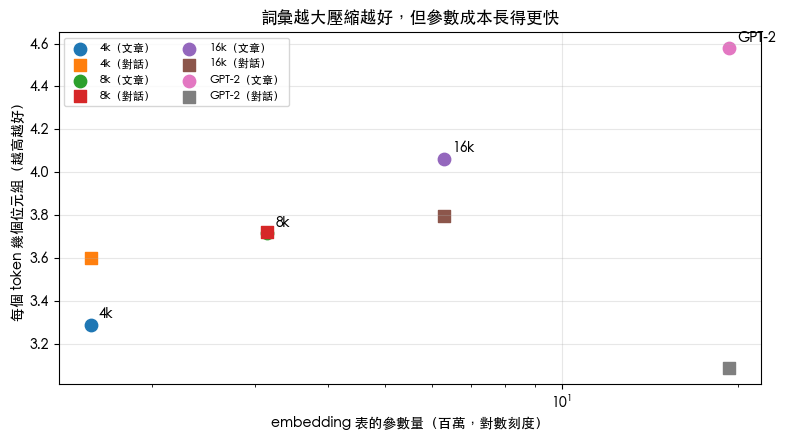

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (v, fw, by, *_ ) in results.items():
    emb = v * d_model / 1e6
    ax.scatter(emb, fw, s=80, label=f"{name}（文章）")
    ax.scatter(emb, by, s=80, marker="s", label=f"{name}（對話）")
    ax.annotate(name, (emb, fw), textcoords="offset points", xytext=(6, 4))
ax.set_xscale("log")
ax.set_xlabel("embedding 表的參數量（百萬，對數刻度）")
ax.set_ylabel("每個 token 幾個位元組（越高越好）")
ax.set_title("詞彙越大壓縮越好，但參數成本長得更快")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**怎麼讀這些數字**（同一份文字，B/tok 越高 = token 越少）：

| 從 → 到 | 文章少了幾 % token | 對話少了幾 % token | embedding 參數 |
|---|---|---|---|
| 4k → 8k | 11% | 3% | 1.6M → 3.1M |
| 8k → 16k | 9% | 2% | 3.1M → 6.3M（翻倍） |

（百分比 = 1 − 舊 B/tok ÷ 新 B/tok，用上表的數字算。）

- **8k → 16k 的回報很小**，尤其在對話文字上只少 2%，參數卻翻倍。
- ⭐ **GPT-2 在對話文字上反而最差**（3.09 B/tok，比我們的 4k 還低）：它的詞彙表沒見過 `<|item|>`，
  每個特殊標記都被切成 5 塊。**大的詞彙表不等於適合你的資料。**

## 7. 切出來長什麼樣子

把一筆買家資料的每個 token 用 `|` 分開印出來。

In [13]:
example = buyer_sample[3]
pieces = [sp8k.id_to_piece(i) for i in encode(sp8k, example)]
print(f"{len(example)} 個字元 → {len(pieces)} 個 token\n")
print("|".join(p.replace("\n", "⏎") for p in pieces))

676 個字元 → 180 個 token

<|item|>|st|ove|<|end|>|<|attrs|>|f|uel|,|▁age|,|▁working|,|▁condition|<|end|>|<|persona|>|Ava|,|▁who|▁works|▁long|▁hours|▁and|▁has|▁little|▁free|▁time|▁and|▁lives|▁in|▁a|▁small|▁apartment|.|<|end|>|<|log|>|Jonah|:|▁How|▁old|▁is|▁the|▁st|ove|?|▁Looks|▁matter|▁to|▁me|.|⏎|You|:|▁About|▁three|▁years|▁old|.|▁I|▁promise|.|⏎|Jonah|:|▁Hm|,|▁okay|.|⏎|Victor|:|▁Quick|▁question|:|▁does|▁the|▁st|ove|▁work|▁properly|?|▁Performance|▁is|▁what|▁I|▁care|▁about|.|⏎|You|:|▁So|,|▁one|▁burn|er|▁doesn|'|t|▁light|.|⏎|Victor|:|▁Yikes|.|▁That|▁changes|▁things|▁a|▁lot|.|▁I|▁need|▁it|▁to|▁perform|▁better|.|⏎|Ava|:|▁Ugh|,|▁that|'|s|▁a|▁real|▁problem|▁for|▁me|.|⏎|Ava|:|▁So|,|▁is|▁it|▁gas|▁or|▁electric|?|▁I|▁don|'|t|▁have|▁much|▁room|.|⏎|You|:|▁Elect|ric|▁co|il|.|▁I|▁promise|.|<|end|>|<|react|>|Ava|:|▁That|'|s|▁going|▁to|▁knock|▁the|▁price|▁down|.|<|interest|>|+|0|<|end|>


In [14]:
for price in ["$1,234", "$12.50", "2,500"]:
    print(price, "→", [sp8k.id_to_piece(i) for i in encode(sp8k, price)])

$1,234 → ['$', '1', ',', '2', '3', '4']
$12.50 → ['$', '1', '2', '.', '5', '0']
2,500 → ['2', ',', '5', '0', '0']


- 特殊標記每個都是**一個** token。
- 數字被拆成一位一位（`split_digits=True`），模型處理價格時看到的是規則的位數，不是隨機的數字片段。

## 結論

正式版選了 **8,192**（`sellanything_ml/llm/tokenizer.py`，用 1.7 億字元訓練）。理由跟這本筆記本的數字一樣：
從 8k 到 16k，對話文字只少一點點 token，但 embedding 參數翻倍；GPT-2 更是貴好幾倍。

In [15]:
print(f"整本跑了 {(time.time() - START) / 60:.1f} 分鐘")

整本跑了 0.3 分鐘
